<a href="https://colab.research.google.com/github/lari-cmd/python-practice-algos-1/blob/student/hw_4_borisova_m_m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Базовое ДЗ (обязательная часть)

In [2]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

california_data = fetch_california_housing(as_frame=True)
df = california_data.frame

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


EDA

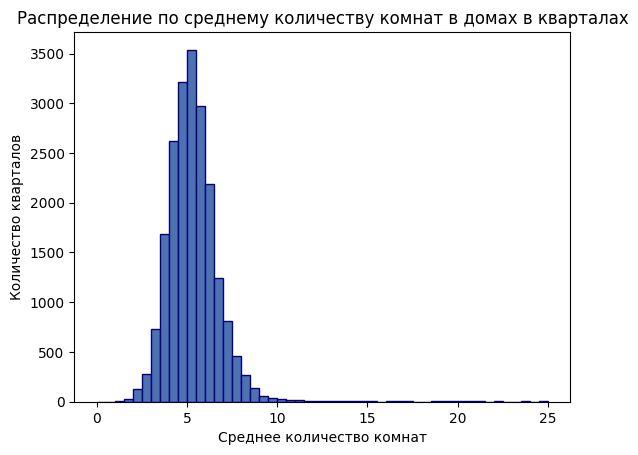

In [32]:
# гистограмма (распределение по количеству комнат в домах)

plt.hist(df['AveRooms'], bins=50, range=(0, 25), color='#4c72b0', edgecolor='navy', linewidth=1)
plt.title('Распределение по среднему количеству комнат в домах в кварталах')
plt.xlabel('Среднее количество комнат')
plt.ylabel('Количество кварталов')
plt.show()

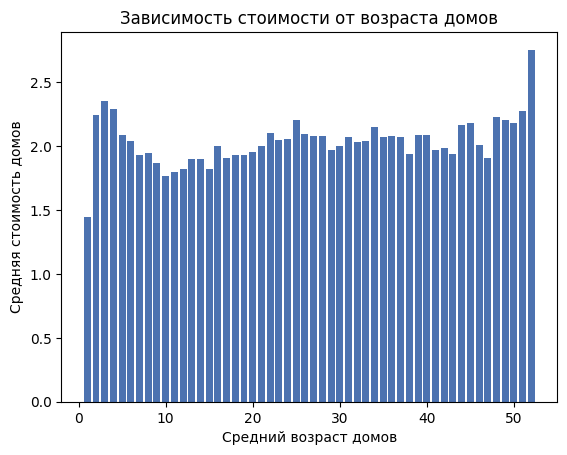

In [39]:
# столбчатая диаграмма (зависимость стоимости от возраста домов)
rate = df.groupby('HouseAge')['MedHouseVal'].mean().sort_values()

plt.bar(rate.index, rate.values, color='#4c72b0')
plt.title('Зависимость стоимости от возраста домов')
plt.xlabel('Средний возраст домов')
plt.ylabel('Средняя стоимость домов')
plt.show()

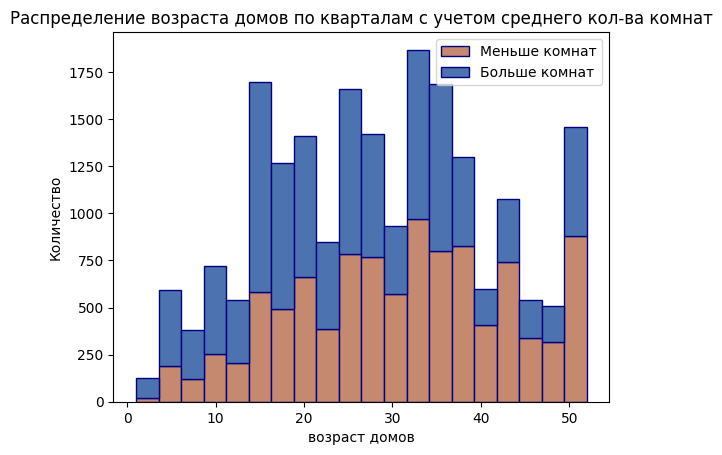

In [45]:
# гистограмма с несколькими признаками
low = df[df['AveRooms'] < df['AveRooms'].median()]['HouseAge']
high = df[df['AveRooms'] >= df['AveRooms'].median()]['HouseAge']
plt.hist([low, high], bins=20, stacked=True, color=["#c4896e", '#4c72b0'], label=['Меньше комнат', 'Больше комнат'], edgecolor='navy', linewidth=1)
plt.title('Распределение возраста домов по кварталам с учетом среднего кол-ва комнат')
plt.xlabel('возраст домов')
plt.ylabel('Количество')
plt.legend()
plt.show()

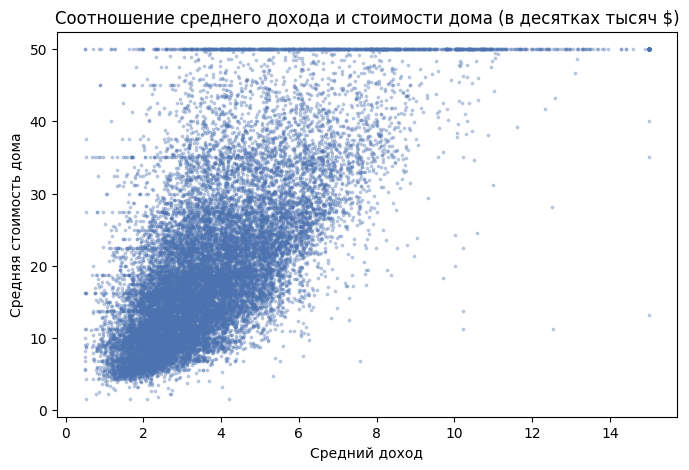

In [52]:
# диаграмма рассеяния
plt.figure(figsize=(8, 5))
plt.scatter(df['MedInc'], df['MedHouseVal'] * 10, s=3, alpha=0.3, color='#4c72b0')
plt.title('Соотношение среднего дохода и стоимости дома (в десятках тысяч $)')
plt.xlabel('Средний доход')
plt.ylabel('Средняя стоимость дома')
plt.show()

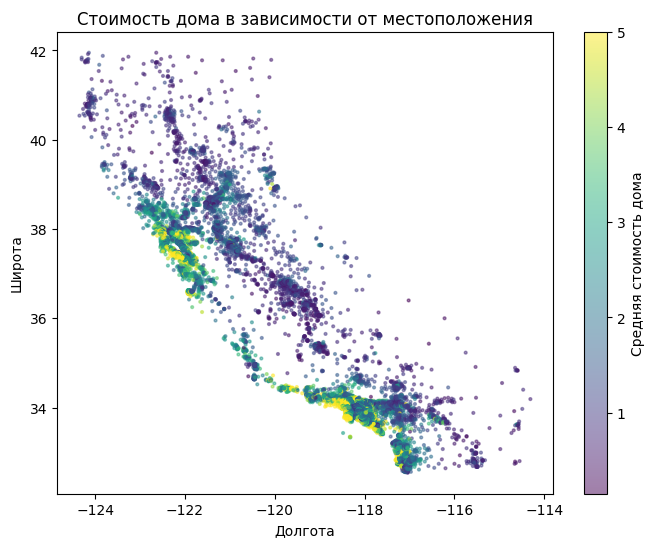

In [69]:
# диаграмма рассеяния с цветами
plt.figure(figsize=(8, 6))
plt.scatter(df['Longitude'], df['Latitude'], c=df['MedHouseVal'], cmap='viridis', s=4, alpha=0.5) # cmap='viridis' — цвето карта Viridis. задаёт, как числовые значения будут превращаться в цвета на графике.
plt.colorbar(label='Средняя стоимость дома')
plt.title('Стоимость дома в зависимости от местоположения')
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.show()

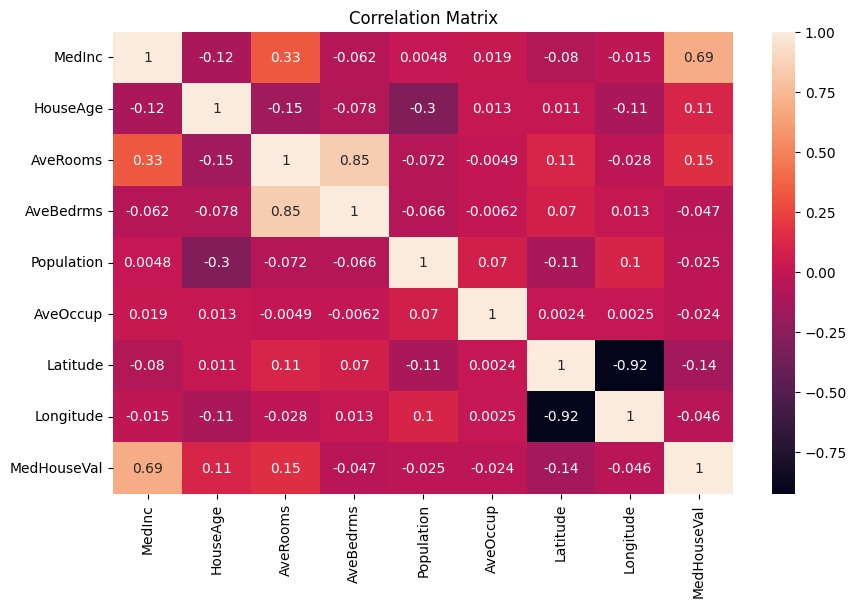

In [46]:
# Тепловая матрица (Корреляционная матрица. Показывает, какие признаки значительно связаны между собой.)
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot = True)
plt.title("Correlation Matrix")
plt.show()

предсказание цены дома с помощью линейной регрессии из scikit-learn (LinearRegression)

In [66]:
num_cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population' 'AveOccup', 'Latitude', 'Longitude']

y = df['MedHouseVal']
x = df.drop('MedHouseVal', axis=1)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

AI = LinearRegression().fit(x_train_scaled, y_train)
default = mean_squared_error(y_test, AI.predict(x_test_scaled))
print(round(default, 4))

0.5559
